# GRPO on the toy model

Notebook 03 gave a base model, notebook 04 a stochastic step with log-probs. Here is the RL loop itself, same structure as `scripts/train_sd3.py` in the official repo, on the toy problem.

Same pieces as before.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
torch.set_num_threads(4)

SURFACE, INK, GRID, MUTED = "#fcfcfb", "#52514e", "#e1e0d9", "#c3c2b7"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def style(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=INK)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(MUTED)


K = 8
RADIUS = 2.0
HALF_ARC = math.pi / K * 0.7
R_STD = 0.08


def sample_data(c):
    center = 2 * math.pi * c / K
    angle = center + (torch.rand(len(c)) * 2 - 1) * HALF_ARC
    radius = RADIUS + R_STD * torch.randn(len(c))
    return torch.stack([radius * torch.cos(angle), radius * torch.sin(angle)], dim=1)


class Velocity(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2 + 1 + K, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t, c):
        onehot = nn.functional.one_hot(c, K).float()
        return self.net(torch.cat([x, t[:, None], onehot], dim=1))


def train_flow(steps=4000, batch=512, lr=2e-3):
    model = Velocity()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses = []
    for _ in range(steps):
        c = torch.randint(K, (batch,))
        x0 = sample_data(c)
        noise = torch.randn_like(x0)
        t = torch.rand(batch)
        xt = (1 - t)[:, None] * x0 + t[:, None] * noise
        loss = ((model(xt, t, c) - (noise - x0)) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        losses.append(loss.item())
    return model, losses


@torch.no_grad()
def sample_ode(model, c, steps=40, noise=None):
    x = torch.randn(len(c), 2) if noise is None else noise.clone()
    ts = torch.linspace(1, 0, steps + 1)
    for t, t_next in zip(ts[:-1], ts[1:]):
        x = x + model(x, t.expand(len(c)), c) * (t_next - t)
    return x


def describe(x, c):
    radius = x.norm(dim=1)
    angle = torch.atan2(x[:, 1], x[:, 0])
    offset = (angle - 2 * math.pi * c / K + math.pi) % (2 * math.pi) - math.pi
    inside = (offset.abs() <= HALF_ARC) & ((radius - RADIUS).abs() <= 3 * R_STD)
    return {
        "inside": inside.float().mean().item(),
        "radius std": radius.std().item(),
        "angle std": offset.std().item(),
    }


def sde_step(v, x, t, t_next, noise_level, t_second, x_next=None):
    dt = t_next - t  # negative, time goes from 1 to 0
    t_safe = t_second if float(t) == 1.0 else t
    std = noise_level * torch.sqrt(t / (1 - t_safe))
    mean = x * (1 + std**2 / (2 * t) * dt) + v * (1 + std**2 * (1 - t) / (2 * t)) * dt
    step_std = std * torch.sqrt(-dt)
    if x_next is None:
        x_next = mean + step_std * torch.randn_like(x)
    log_prob = (
        -((x_next.detach() - mean) ** 2) / (2 * step_std**2)
        - torch.log(step_std)
        - 0.5 * math.log(2 * math.pi)
    ).mean(dim=1)
    return x_next, log_prob, mean, std


base, _ = train_flow()

## Reward

The goal for each class is the middle of its arc. Reward is 1 at the goal and falls off with distance.

The base model spreads points along the whole arc, so there is room to improve. The easy way to get reward is to put every sample on the goal, which kills the spread. That is the toy version of what I want to watch for in SD3.

In [2]:
GOAL_STD = 0.3


def reward_fn(x, c):
    center = 2 * math.pi * c / K
    goal = torch.stack([RADIUS * torch.cos(center), RADIUS * torch.sin(center)], dim=1)
    return torch.exp(-((x - goal) ** 2).sum(dim=1) / (2 * GOAL_STD**2))


c = torch.arange(K).repeat_interleave(2500)
x = sample_ode(base, c, 40)
print(f"base model: reward {reward_fn(x, c).mean().item():.3f}, angle std {describe(x, c)['angle std']:.3f}")

base model: reward 0.679, angle std 0.152


## The loop

One iteration:

1. pick classes, sample a group for each with the SDE step (10 steps, noise 0.7), keep every step and its log-prob
2. reward on the final points
3. advantage = reward minus the group mean, divided by the std of all rewards in the batch, clipped to ±5
4. for each timestep: recompute the log-prob with the current model, ratio to the stored one, PPO clipped loss
5. optional KL to the frozen base model with weight beta: squared difference of the two means over $2\sigma_t^2$

Evaluation is 40 ODE steps from fixed noise.

In [3]:
def grpo(base, iters=150, n_groups=8, group_size=24, steps=10, noise_level=0.7,
         lr=3e-4, clip=0.1, beta=0.0, seed=0, eval_every=10):
    torch.manual_seed(seed)
    model = Velocity()
    model.load_state_dict(base.state_dict())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ts = torch.linspace(1, 0, steps + 1)
    eval_c = torch.arange(K).repeat_interleave(256)
    eval_noise = torch.randn(len(eval_c), 2, generator=torch.Generator().manual_seed(123))
    history = []
    first_ratio = None

    for it in range(iters + 1):
        if it % eval_every == 0:
            x_eval = sample_ode(model, eval_c, 40, eval_noise)
            history.append({"iter": it, "reward": reward_fn(x_eval, eval_c).mean().item(),
                            **describe(x_eval, eval_c)})
        if it == iters:
            break

        # sample groups with the current model
        c = torch.randint(K, (n_groups,)).repeat_interleave(group_size)
        group = torch.arange(n_groups).repeat_interleave(group_size)
        x = torch.randn(len(c), 2)
        traj = []
        with torch.no_grad():
            for i in range(steps):
                v = model(x, ts[i].expand(len(c)), c)
                x_next, logp, _, _ = sde_step(v, x, ts[i], ts[i + 1], noise_level, ts[1])
                traj.append((x, x_next, logp))
                x = x_next

        # advantage: minus the group mean, divided by the std of all rewards
        rewards = reward_fn(x, c)
        group_mean = torch.zeros(n_groups).index_add_(0, group, rewards) / group_size
        adv = ((rewards - group_mean[group]) / (rewards.std() + 1e-4)).clamp(-5, 5)

        for j in torch.randperm(steps).tolist():
            x_j, x_next_j, old_logp = traj[j]
            t = ts[j].expand(len(c))
            _, logp, mean, std = sde_step(model(x_j, t, c), x_j, ts[j], ts[j + 1],
                                          noise_level, ts[1], x_next=x_next_j)
            ratio = torch.exp(logp - old_logp)
            if first_ratio is None:
                first_ratio = (ratio - 1).abs().max().item()
            loss = torch.maximum(-adv * ratio, -adv * ratio.clamp(1 - clip, 1 + clip)).mean()
            if beta > 0:
                with torch.no_grad():
                    _, _, mean_ref, _ = sde_step(base(x_j, t, c), x_j, ts[j], ts[j + 1],
                                                 noise_level, ts[1], x_next=x_next_j)
                loss = loss + beta * (((mean - mean_ref) ** 2).mean(dim=1) / (2 * std**2)).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()

    return model, history, first_ratio

## Runs

Four values of beta. `first ratio - 1` is the on-policy check: before the first update the ratio has to be exactly 1.

In [4]:
runs, models = {}, {}
for beta in (0, 1, 10, 30):
    models[beta], runs[beta], first_ratio = grpo(base, beta=beta)
    first, last = runs[beta][0], runs[beta][-1]
    print(
        f"beta={beta:<3} reward {first['reward']:.3f} -> {last['reward']:.3f}   "
        f"angle std {first['angle std']:.3f} -> {last['angle std']:.3f}   "
        f"first ratio - 1: {first_ratio:.0e}"
    )

beta=0   reward 0.684 -> 0.983   angle std 0.151 -> 0.014   first ratio - 1: 0e+00
beta=1   reward 0.684 -> 0.968   angle std 0.151 -> 0.029   first ratio - 1: 0e+00
beta=10  reward 0.684 -> 0.866   angle std 0.151 -> 0.079   first ratio - 1: 0e+00
beta=30  reward 0.684 -> 0.762   angle std 0.151 -> 0.121   first ratio - 1: 0e+00


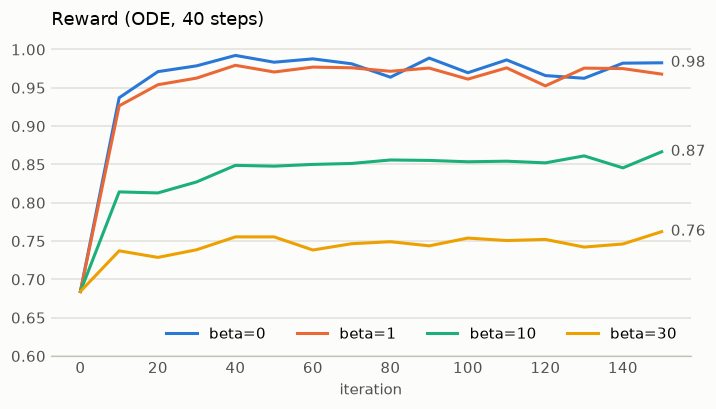

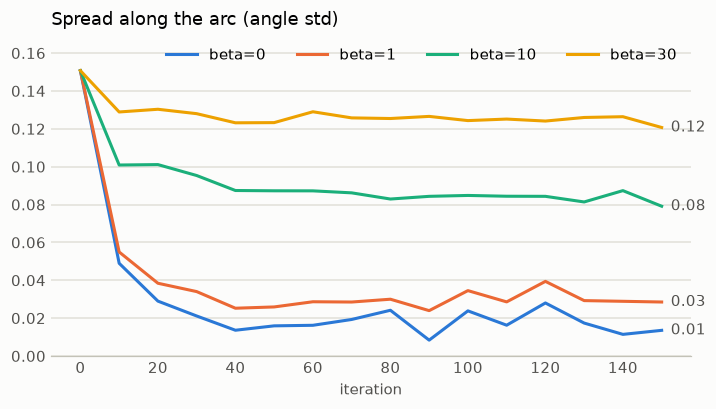

In [5]:
def lines(ax, key, title, gap):
    placed = []
    for (beta, history), color in zip(runs.items(), COLORS):
        xs = [h["iter"] for h in history]
        ys = [h[key] for h in history]
        ax.plot(xs, ys, color=color, lw=2, label=f"beta={beta}")
        if all(abs(ys[-1] - y) > gap for y in placed):
            ax.annotate(f"{ys[-1]:.2f}", (xs[-1], ys[-1]), xytext=(6, 0),
                        textcoords="offset points", va="center", color=INK)
            placed.append(ys[-1])
    style(ax)
    ax.set_xlabel("iteration", color=INK)
    ax.set_title(title, loc="left")


fig, ax = plt.subplots(figsize=(7.5, 3.8), dpi=110, facecolor=SURFACE)
lines(ax, "reward", "Reward (ODE, 40 steps)", gap=0.03)
ax.set_ylim(0.6, 1.02)
ax.legend(frameon=False, loc="lower right", ncols=4)
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.8), dpi=110, facecolor=SURFACE)
lines(ax, "angle std", "Spread along the arc (angle std)", gap=0.008)
ax.set_ylim(0, 0.17)
ax.legend(frameon=False, loc="upper right", ncols=4)
plt.show()

Without KL the reward goes from 0.68 to about 0.94 in 10 iterations and ends at 0.98. The spread along the arc goes from 0.151 to 0.014, ten times narrower.

beta trades one for the other: at 10 the reward ends at 0.87 with spread 0.079, at 30 at 0.76 with 0.121.

The beta=0 and beta=1 curves wobble after they flatten out instead of staying at the top.

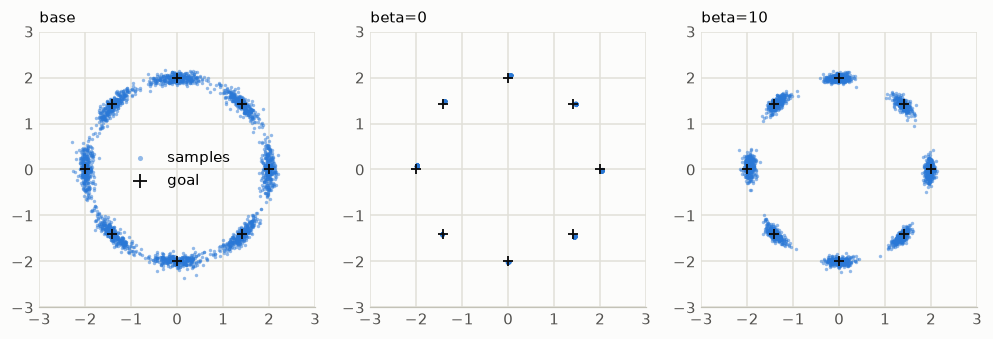

In [6]:
c = torch.arange(K).repeat_interleave(300)
noise = torch.randn(len(c), 2, generator=torch.Generator().manual_seed(5))
panels = {"base": base, "beta=0": models[0], "beta=10": models[10]}
goals = torch.stack([RADIUS * torch.cos(2 * math.pi * torch.arange(K) / K),
                     RADIUS * torch.sin(2 * math.pi * torch.arange(K) / K)], dim=1)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), dpi=110, facecolor=SURFACE)
for ax, (name, model) in zip(axes, panels.items()):
    x = sample_ode(model, c, 40, noise)
    style(ax, grid="both")
    ax.scatter(x[:, 0], x[:, 1], s=5, color=COLORS[0], alpha=0.5, lw=0, label="samples")
    ax.scatter(goals[:, 0], goals[:, 1], s=40, marker="+", color="#0b0b0b", lw=1.2, label="goal")
    ax.set_aspect("equal")
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_title(name, loc="left", fontsize=10)
axes[0].legend(frameon=False, loc="center", markerscale=1.5)
plt.show()

With beta=0 every class is a dot on its goal. With beta=10 the arcs are shorter but still arcs.

## Notes for later

- the loop works: ratio is 1 on the first step and the reward goes up
- without KL the model gets its reward by collapsing each class to a point. Reward alone would not show this, the spread number does
- beta has to be found by looking at the spread, the value here means nothing for SD3 (different dimensions, different reward scale)
- once the reward is near 1 the advantages are mostly noise (the std in the denominator is tiny) and the model wanders. Early stopping or a schedule may be needed